[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/01-filtro-antispam-naive-bayes.ipynb)

# Filtro antispam com Naive Bayes

Mensagens curtas de celular, rotuladas como spam ou ham (mensagem legitima), e o exemplo classico de classificador de texto. O conjunto e o SMS Spam Collection, numero 228 do repositorio da UCI, reunido por Almeida, Hidalgo e Yamakami. O arquivo e pequeno e baixa direto, sem cadastro.

Este caderno estima, so com NumPy, um Naive Bayes multinomial com suavizacao de Laplace e compara a probabilidade, casa a casa, com o `MultinomialNB` do scikit-learn.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Pense na caixa de entrada de um celular em Manaus. Uma mensagem diz "mae, chego as 18h". Outra diz "voce ganhou um premio, ligue agora". Ninguem multiplica probabilidades de cabeca, mas o habito e o mesmo do algoritmo: algumas palavras quase so aparecem em propaganda, outras aparecem nos dois lados, e o conjunto empurra a decisao.

O Naive Bayes formaliza esse habito. Ele pergunta, para cada classe, quao surpreendente seria a mensagem se ela viesse daquela classe, e mistura isso com a frequencia da classe. Spam e minoria. Uma palavra rara de propaganda precisa ser forte o bastante para vencer esse prior.


## 2) Fundamentação matemática

O teorema de Bayes inverte a pergunta. Em vez de perguntar so quao tipico e o texto dentro de uma classe, calculamos a chance da classe depois de ler o texto:

$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$

- $P(y \mid x)$ e a probabilidade da classe $y$ depois de observar $x$. E a saida do classificador.
- $P(x \mid y)$ e a verossimilhanca: a chance de ver esse texto se a classe for $y$.
- $P(y)$ e o prior, a frequencia da classe antes de olhar o texto.
- $P(x)$ e a evidencia. Ela nao depende de $y$, entao nao muda qual classe ganha. Na hora de decidir, comparamos $P(x \mid y)\,P(y)$.

A hipotese de independencia condicional, a parte ingênua do nome, diz que, dada a classe, uma palavra nao informa a outra:

$$
P(x \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
$$

- $x_j$ e a contagem da palavra $j$.
- $d$ e o tamanho do vocabulario.
- O produto e falso em frases reais ("nao" muda "bom"), mas o erro muitas vezes se reparte e o sinal de cada palavra ainda aponta a classe certa.

No modelo multinomial a probabilidade de uma palavra e a fatia dela nas contagens da classe. A suavizacao de Laplace soma $\alpha$ para uma palavra nunca vista nao zerar o produto inteiro:

$$
\hat{P}(w \mid y) = \frac{n_{y,w} + \alpha}{n_y + \alpha \, |V|}
$$

- $n_{y,w}$ e quantas vezes a palavra $w$ apareceu na classe $y$.
- $n_y$ e a soma de todas as contagens da classe.
- $|V|$ e o numero de palavras do vocabulario.
- $\alpha$ e a forca da suavizacao. Com $\alpha = 1$ ha uma ocorrencia ficticia de cada palavra em cada classe.

Mil probabilidades pequenas, multiplicadas, estouram para zero no computador. O logaritmo transforma o produto em soma:

$$
\log P(y \mid x) \propto \log P(y) + \sum_{j=1}^{d} x_j \, \log \hat{P}(w_j \mid y)
$$

- $\log P(y)$ e o prior em escala de log.
- $x_j \log \hat{P}(w_j \mid y)$ pesa a palavra pela contagem dela neste texto. Palavra ausente entra com zero.
- A classe escolhida e a de maior soma. Para converter as somas em probabilidades que somam 1, subtraimos o log-sum-exp de todas as classes.


## 3) Visualização

Os textos desta colecao estao em ingles, porque foi assim que a UCI publicou o corpus. Abaixo: o equilibrio das classes, o tamanho das mensagens e as palavras mais repetidas de cada lado. A diferenca de contagem ainda nao e o modelo; e o retrato cru que o modelo vai transformar em log-probabilidade.


mensagens 5574
rotulo
ham     4827
spam     747
Name: count, dtype: int64
fonte: UCI SMS Spam Collection, conjunto 228


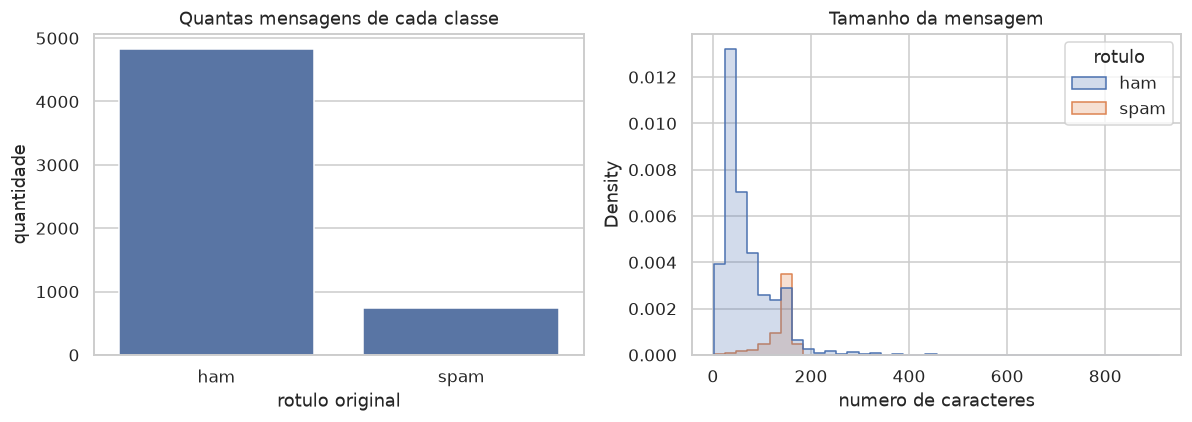

treino 4180 teste 1394 spam no teste 187


In [2]:
import zipfile

from sklearn.model_selection import train_test_split

arquivo = baixar(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
    PASTA_DADOS / "smsspamcollection.zip",
)
with zipfile.ZipFile(arquivo) as pacote:
    bruto = pacote.read("SMSSpamCollection")
texto = bruto.decode("utf-8", errors="replace")
mensagens, rotulos = [], []
for linha in texto.splitlines():
    if "\t" not in linha:
        continue
    rotulo, mensagem = linha.split("\t", 1)
    mensagens.append(mensagem)
    rotulos.append(rotulo)

df = pd.DataFrame({"mensagem": mensagens, "rotulo": rotulos})
df["y"] = (df["rotulo"] == "spam").astype(int)
df["tamanho"] = df["mensagem"].str.len()
print("mensagens", len(df))
print(df["rotulo"].value_counts())
print("fonte: UCI SMS Spam Collection, conjunto 228")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="rotulo", ax=eixos[0], color="#4c72b0")
eixos[0].set_title("Quantas mensagens de cada classe")
eixos[0].set_xlabel("rotulo original")
eixos[0].set_ylabel("quantidade")
sns.histplot(data=df, x="tamanho", hue="rotulo", bins=40, element="step", stat="density", ax=eixos[1])
eixos[1].set_title("Tamanho da mensagem")
eixos[1].set_xlabel("numero de caracteres")
plt.tight_layout()
plt.show()

X_treino_txt, X_teste_txt, y_treino, y_teste = train_test_split(
    df["mensagem"].tolist(),
    df["y"].to_numpy(),
    test_size=0.25,
    random_state=0,
    stratify=df["y"].to_numpy(),
)
print("treino", len(y_treino), "teste", len(y_teste), "spam no teste", int(y_teste.sum()))


## 4) Implementação do zero

O vetor de contagens e ajustado so no treino. Palavra que so existe no teste e ignorada: nao da para estimar a probabilidade dela. `alpha=1` e a suavizacao de Laplace da formula acima. A classe positiva, codificada como 1, e spam.


vocabulario 7431 matriz (4180, 7431)


prior de spam 0.13397129186602877


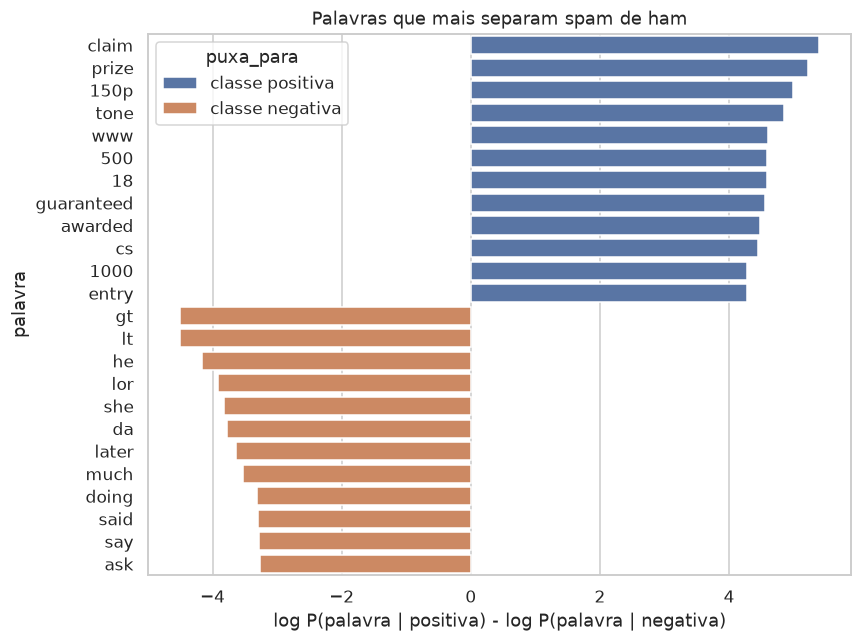

In [3]:
from mlalgos import BagOfWords, MultinomialNB

vetor = BagOfWords()
X_treino = vetor.fit_transform(X_treino_txt)
X_teste = vetor.transform(X_teste_txt)
print("vocabulario", len(vetor.vocabulary_), "matriz", X_treino.shape)

nb = MultinomialNB(alpha=1.0).fit(X_treino, y_treino)
print("prior de spam", float(np.exp(nb.class_log_prior_[list(nb.classes_).index(1)])))
indice = {classe: i for i, classe in enumerate(nb.classes_)}
delta = nb.feature_log_prob_[indice[1]] - nb.feature_log_prob_[indice[0]]
vocabulario = np.empty(len(vetor.vocabulary_), dtype=object)
for token, coluna in vetor.vocabulary_.items():
    vocabulario[coluna] = token
ordem = np.argsort(delta)
k = 12
tabela = pd.DataFrame({
    "palavra": np.concatenate([vocabulario[ordem[-k:][::-1]], vocabulario[ordem[:k]]]),
    "diferenca_de_log": np.concatenate([delta[ordem[-k:][::-1]], delta[ordem[:k]]]),
    "puxa_para": ["classe positiva"] * k + ["classe negativa"] * k,
})
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=tabela, y="palavra", x="diferenca_de_log", hue="puxa_para", dodge=False, ax=ax)
ax.set_title('Palavras que mais separam spam de ham')
ax.set_xlabel("log P(palavra | positiva) - log P(palavra | negativa)")
plt.tight_layout()
plt.show()


## 5) Implementação com scikit-learn

Primeiro os dois modelos recebem a mesma matriz de contagens. Se a conta estiver certa, as probabilidades coincidem ate o arredondamento. Depois, um `Pipeline` do scikit-learn refaz o caminho inteiro com o proprio vetorizador, que e o jeito usual de colocar o filtro em producao.


In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB as SkMultinomialNB
from sklearn.pipeline import Pipeline

sk = SkMultinomialNB(alpha=1.0).fit(X_treino, y_treino)
diferenca = np.max(np.abs(nb.predict_proba(X_teste) - sk.predict_proba(X_teste)))
acordo = float(np.mean(nb.predict(X_teste) == sk.predict(X_teste)))
print(f"maior diferenca absoluta entre probabilidades: {diferenca:.3e}")
print(f"concordancia das classes previstas: {acordo:.3f}")

cano = Pipeline([
    ("contagem", CountVectorizer()),
    ("nb", SkMultinomialNB(alpha=1.0)),
])
cano.fit(X_treino_txt, y_treino)
print("acuracia do pipeline no teste", float(cano.score(X_teste_txt, y_teste)))


maior diferenca absoluta entre probabilidades: 1.421e-14
concordancia das classes previstas: 1.000
acuracia do pipeline no teste 0.9842180774748924


## 6) Avaliação

Precisao responde: das mensagens que o filtro barrou, quantas eram spam de fato. Revocacao responde: de todo o spam, quanto o filtro pegou. O F1 e a media harmonica das duas. A ROC-AUC mede a ordenacao dos escores, sem cravar o limiar 0,5. A acuracia sozinha engana, porque ham e a grande maioria.


acuracia 0.984 | baseline da classe majoritaria 0.866
precisao 0.977 | revocacao 0.904 | f1 0.939 | roc_auc 0.974
RESUMO_METRICAS {"modelo": "multinomial_nb", "acuracia": 0.9842180774748924, "precisao": 0.976878612716763, "revocacao": 0.9037433155080213, "f1": 0.9388888888888889, "roc_auc": 0.9742500299057636, "baseline_majoritaria": 0.8658536585365854}


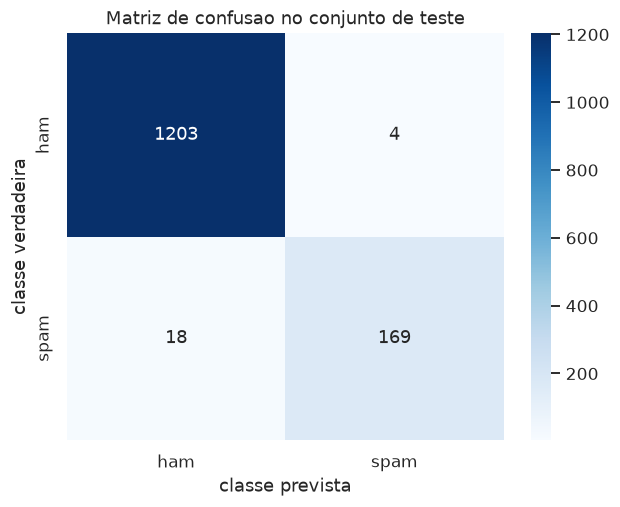

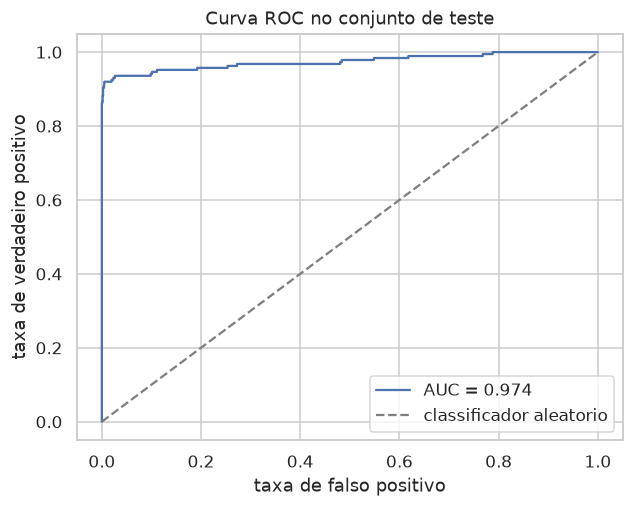

In [5]:
from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = nb.predict(X_teste)
y_escore = nb.predict_proba(X_teste)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'multinomial_nb',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()


## 7) Desafios

1. Refaca o ajuste com `alpha` igual a 0,1 e igual a 5. Qual dos dois deixa o modelo mais desconfiado de uma palavra que apareceu uma vez so?
2. Retire do vocabulario as 30 palavras mais frequentes do treino e meça de novo o F1. Elas ajudavam ou so ocupavam coluna?
3. Escolha um falso positivo no teste, liste as tres palavras que mais aumentaram o log da classe spam nessa mensagem e diga se um humano cairia na mesma armadilha.
